# 05 - Tuning and the Final Model

Used car price prediction, step 5 of the project. Each step has its own notebook:

- 01 - data loading, exploration, cleaning, and preprocessing
- 02 - exploratory data analysis
- 03 - feature selection
- 04 - model development
- **05 - tuning and the final model (this notebook)**

**Goal:** improve the two shortlisted models by tuning their settings, choose the final model, test it once, and save it for the Streamlit app.

**Shortlist from notebook 04:** Gradient Boosting and Random Forest, both trained on raw price.

**How:** `RandomizedSearchCV` tries 25 random combinations of settings for each model. Every combination is scored with 5-fold cross-validation on the **training data**. The best combination of each model is compared, and the winner becomes the final model. The test set is used **once**, at the end, to report how the final model performs on new cars. The model that gets saved is exactly the model that was tested.

Note: this notebook takes roughly 20 to 30 minutes to run in Colab. Keep the browser tab open and the computer awake.

## 1. Setup

**Important for the saved model:** a model saved with one scikit-learn version can fail to load with another. The Streamlit app on your PC will use scikit-learn 1.9.1, so this notebook installs exactly that version first. If the check after it fails, use **Runtime > Restart session** in Colab and run all cells again.

In [1]:
# Install the exact scikit-learn version that the PC (and requirements.txt) will use
%pip install -q scikit-learn==1.9.1

In [2]:
# Import the libraries used in this notebook
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import joblib
import sklearn

from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")       # keep the output readable
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)   # folder for the charts

# Print the library versions
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scipy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

# Stop here if the scikit-learn version is wrong
assert sklearn.__version__ == "1.9.1", (
    "scikit-learn is " + sklearn.__version__ + " but 1.9.1 is needed. "
    "Use Runtime > Restart session, then run all cells again.")

pandas: 2.2.3
numpy: 2.4.6
scipy: 1.16.3
scikit-learn: 1.9.1
joblib: 1.6.0


In [3]:
# A small helper: tidy the layout, save the chart as a PNG file, then show it
def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the data and the selected features

In [4]:
# Load the cleaned data (notebook 01) and the selected features (notebook 03).
# First try to read both straight from the GitHub repo. If the repo is private, or the files
# have not been pushed yet, fall back to uploading them by hand (a file picker appears twice).
import urllib.request

BASE_URL = "https://raw.githubusercontent.com/MirajAdhikari/used-car-price-prediction/main/data/processed/"

try:
    clean = pd.read_csv(BASE_URL + "cardekho_cleaned.csv")
    selection = json.load(urllib.request.urlopen(BASE_URL + "selected_features.json"))
    print("Loaded both files from GitHub.")
except Exception:
    from google.colab import files
    # The upload window can only pick files from one folder at a time,
    # so we ask for the two files separately. Each file is saved in the current folder.
    print("Step 1 of 2: choose cardekho_cleaned.csv")
    files.upload()
    print("Step 2 of 2: choose selected_features.json")
    files.upload()
    clean = pd.read_csv("cardekho_cleaned.csv")
    with open("selected_features.json") as file:
        selection = json.load(file)
    print("Loaded both files from the upload.")

print("Shape (rows, columns):", clean.shape)


Step 1 of 2: choose cardekho_cleaned.csv


Saving cardekho_cleaned.csv to cardekho_cleaned.csv
Step 2 of 2: choose selected_features.json


Saving selected_features.json to selected_features.json
Loaded both files from the upload.
Shape (rows, columns): (15240, 13)


In [5]:
# The features chosen in notebook 03
numeric_features = selection["numeric_features"]
categorical_features = selection["categorical_features"]
print("Numeric features:    ", numeric_features)
print("Categorical features:", categorical_features)

# The same 80/20 split as in the earlier notebooks (random_state=42)
X = clean[numeric_features + categorical_features]
y = clean["selling_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nTraining rows:", len(X_train), "| Test rows:", len(X_test))

Numeric features:     ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Categorical features: ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']

Training rows: 12192 | Test rows: 3048


## 3. Metrics and models

The same four metrics as in notebook 04, with errors in lakh rupees (1 lakh = 100,000 rupees): RMSE, MAE, R2, and the median % error.

Both shortlisted models are trained on **raw price**, so the pipeline predicts rupees directly. The preprocessing (standardize numeric columns, one-hot encode text columns) is inside the pipeline.

In [6]:
# Median percentage error: the middle value of |actual - predicted| / actual, as a percent
def median_pct_error(y_true, y_pred):
    return np.median(np.abs(y_true - y_pred) / y_true) * 100

# All four metrics for a set of predictions (errors in lakh rupees)
def evaluate(y_true, y_pred):
    return {
        "RMSE (lakh)": np.sqrt(mean_squared_error(y_true, y_pred)) / 100_000,
        "MAE (lakh)": mean_absolute_error(y_true, y_pred) / 100_000,
        "R2": r2_score(y_true, y_pred),
        "Median % error": median_pct_error(y_true, y_pred),
    }

# The scores to collect in every cross-validation fold (all in rupees)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
    "median_pct": make_scorer(median_pct_error, greater_is_better=False),
}

# Preprocessing: the same idea as in notebooks 01 and 04
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ])

# The two models, with their default settings (the starting point)
base_models = {
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

def build_model(model_name):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", clone(base_models[model_name])),
    ])

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

## 4. Starting point: default settings

First the cross-validated scores of the two models with default settings. Tuned models are compared against these, so we can see whether tuning really helps.

In [7]:
default_rows = []
for model_name in base_models:
    scores = cross_validate(build_model(model_name), X_train, y_train, cv=kfold, scoring=scoring)
    default_rows.append({
        "Model": model_name,
        "Settings": "default",
        "CV RMSE (lakh)": -scores["test_rmse"].mean() / 100_000,
        "CV MAE (lakh)": -scores["test_mae"].mean() / 100_000,
        "CV R2": scores["test_r2"].mean(),
        "CV median % error": -scores["test_median_pct"].mean(),
    })

pd.DataFrame(default_rows).round(3)

,Model,Settings,CV RMSE (lakh),CV MAE (lakh),CV R2,CV median % error
0,Gradient Boosting,default,2.299,1.01,0.922,10.238
1,Random Forest,default,2.315,1.01,0.921,9.968


## 5. Tuning with RandomizedSearchCV

For each model we define a range of values for its main settings. `RandomizedSearchCV` picks 25 random combinations, scores each with 5-fold cross-validation (so 25 x 5 trainings per model), and keeps the combination with the lowest RMSE. Trying random combinations is much faster than trying every combination and usually finds almost as good a result.

What the settings do:

- **Gradient Boosting:** `learning_rate` (how big each correction step is), `max_iter` (the number of boosting rounds), `max_leaf_nodes` and `min_samples_leaf` (how complex each tree can be), and `l2_regularization` (a penalty against over-fitting).
- **Random Forest:** `n_estimators` (the number of trees), `max_depth`, `min_samples_leaf`, and `min_samples_split` (how deep and detailed each tree can get), and `max_features` (the share of features each split looks at).

The Random Forest settings are limited to at most 300 trees, so the saved model file stays small enough for GitHub (the limit is 100 MB per file).

In [8]:
# The settings to search. The "model__" prefix means "a setting of the model inside the pipeline".
search_spaces = {
    "Gradient Boosting": {
        "model__learning_rate": loguniform(0.02, 0.3),
        "model__max_iter": randint(150, 600),
        "model__max_leaf_nodes": randint(15, 64),
        "model__min_samples_leaf": randint(5, 60),
        "model__l2_regularization": loguniform(1e-3, 10),
    },
    "Random Forest": {
        "model__n_estimators": randint(100, 301),
        "model__max_depth": [None, 20, 30],
        "model__min_samples_leaf": randint(1, 6),
        "model__min_samples_split": randint(2, 11),
        "model__max_features": [1.0, 0.5, 0.33],
    },
}

N_ITER = 25      # random combinations tried per model

In [9]:
start = time.time()
searches = {}

for model_name, space in search_spaces.items():
    search = RandomizedSearchCV(
        estimator=build_model(model_name),
        param_distributions=space,
        n_iter=N_ITER,
        scoring=scoring,
        refit="rmse",          # the best combination is the one with the lowest RMSE
        cv=kfold,
        random_state=42,
        n_jobs=1,
    )
    search.fit(X_train, y_train)          # also re-trains the best combination on all training data
    searches[model_name] = search
    print(f"Finished {model_name} after {round((time.time() - start) / 60, 1)} minutes")

Finished Gradient Boosting after 18.0 minutes
Finished Random Forest after 33.1 minutes


In [10]:
# The cross-validated scores of the best combination found for each model
tuned_rows = []
for model_name, search in searches.items():
    i = search.best_index_
    results = search.cv_results_
    tuned_rows.append({
        "Model": model_name,
        "Settings": "tuned",
        "CV RMSE (lakh)": -results["mean_test_rmse"][i] / 100_000,
        "CV MAE (lakh)": -results["mean_test_mae"][i] / 100_000,
        "CV R2": results["mean_test_r2"][i],
        "CV median % error": -results["mean_test_median_pct"][i],
    })

comparison = pd.DataFrame(default_rows + tuned_rows).sort_values(["Model", "Settings"],
                                                                 ascending=[True, False])
print(comparison.round(3).to_string(index=False))

print("\nBest settings found:")
for model_name, search in searches.items():
    print(model_name)
    for setting, value in search.best_params_.items():
        shown = round(value, 4) if isinstance(value, float) else value
        print("   ", setting.replace("model__", ""), "=", shown)

            Model Settings  CV RMSE (lakh)  CV MAE (lakh)  CV R2  CV median % error
Gradient Boosting    tuned           2.142          0.974  0.932             10.118
Gradient Boosting  default           2.299          1.010  0.922             10.238
    Random Forest    tuned           2.270          0.982  0.923              9.822
    Random Forest  default           2.315          1.010  0.921              9.968

Best settings found:
Gradient Boosting
    l2_regularization = 4.3379
    learning_rate = 0.0403
    max_iter = 509
    max_leaf_nodes = 18
    min_samples_leaf = 6
Random Forest
    max_depth = None
    max_features = 0.33
    min_samples_leaf = 2
    min_samples_split = 3
    n_estimators = 289


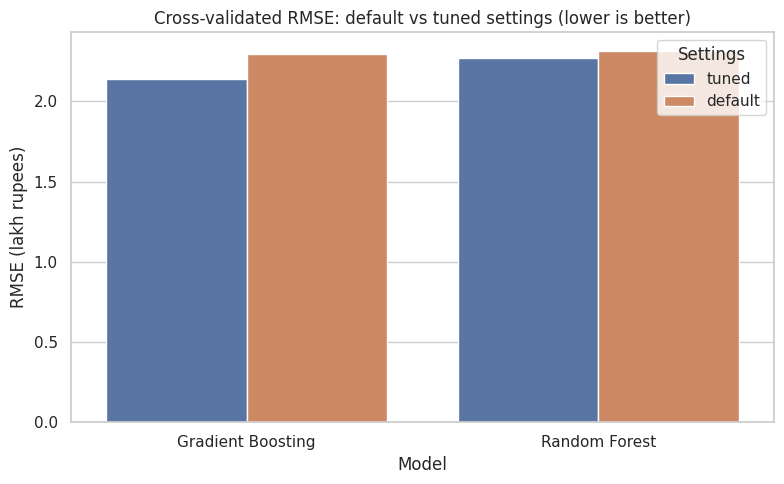

In [11]:
# Chart: cross-validated RMSE, default vs tuned
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=comparison, x="Model", y="CV RMSE (lakh)", hue="Settings", ax=ax)
ax.set_title("Cross-validated RMSE: default vs tuned settings (lower is better)")
ax.set_ylabel("RMSE (lakh rupees)")
save_fig("13_tuning_results")

## 6. Choosing the final model

The final model is the tuned model with the lowest cross-validated RMSE. Choosing by cross-validation on the training data (not by the test set) keeps the test set an honest check.

In [12]:
tuned_table = pd.DataFrame(tuned_rows).sort_values("CV RMSE (lakh)").reset_index(drop=True)
final_name = tuned_table.iloc[0]["Model"]
final_model = searches[final_name].best_estimator_      # already trained on all training data

print("Final model:", final_name)
print("Its cross-validated RMSE (lakh):", round(tuned_table.iloc[0]["CV RMSE (lakh)"], 3))
print("The other tuned model:", tuned_table.iloc[1]["Model"],
      "with", round(tuned_table.iloc[1]["CV RMSE (lakh)"], 3))

Final model: Gradient Boosting
Its cross-validated RMSE (lakh): 2.142
The other tuned model: Random Forest with 2.27


## 7. Test set evaluation of the final model

The final model is now scored on the 20% of cars it has never seen. This is done once, and only for the final model.

In [13]:
test_predictions = final_model.predict(X_test)          # predicted prices in rupees
test_scores = evaluate(y_test, test_predictions)
print({k: round(float(v), 3) for k, v in test_scores.items()})

{'RMSE (lakh)': 6.044, 'MAE (lakh)': 1.113, 'R2': 0.717, 'Median % error': 10.219}


As in notebook 04, a few extremely expensive cars can dominate RMSE and R2. We check that again here. The second line is a diagnostic to understand the result, not a score to report.

In [14]:
highest_training_price = y_train.max()
above_range = (y_test > highest_training_price).values
print("Most expensive training car (lakh):", highest_training_price / 100_000)
print("Test cars above that price:", above_range.sum())

within = ~above_range
scores_within = evaluate(y_test[within], test_predictions[within])
print("\nAll test cars:               ", {k: round(float(v), 3) for k, v in test_scores.items()})
print("Without cars above the range:", {k: round(float(v), 3) for k, v in scores_within.items()})

Most expensive training car (lakh): 145.0
Test cars above that price: 2

All test cars:                {'RMSE (lakh)': 6.044, 'MAE (lakh)': 1.113, 'R2': 0.717, 'Median % error': 10.219}
Without cars above the range: {'RMSE (lakh)': 2.13, 'MAE (lakh)': 0.981, 'R2': 0.927, 'Median % error': 10.212}


In [15]:
# The 5 test cars where the final model was furthest off
largest = pd.DataFrame({
    "brand": clean.loc[y_test.index, "brand"],
    "model": clean.loc[y_test.index, "model"],
    "actual (lakh)": y_test / 100_000,
    "predicted (lakh)": test_predictions / 100_000,
})
largest["error (lakh)"] = (largest["actual (lakh)"] - largest["predicted (lakh)"]).abs()
largest.sort_values("error (lakh)", ascending=False).head(5).round(1)

,brand,model,actual (lakh),predicted (lakh),error (lakh)
3784,Ferrari,GTC4Lusso,395.0,104.0,291.0
10869,Rolls-Royce,Ghost,242.0,128.6,113.4
10889,Mercedes-Benz,S-Class,110.0,69.7,40.3
12872,Bentley,Continental,81.0,44.0,37.0
7268,Mercedes-Benz,CLS,42.0,71.3,29.3


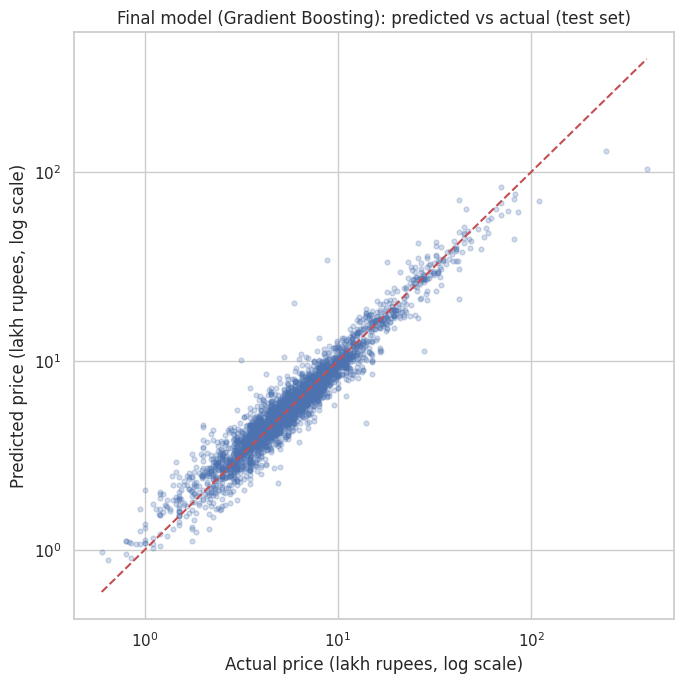

In [16]:
# Chart: predicted vs actual price for the final model (each point is one test car)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test / 100_000, test_predictions / 100_000, alpha=0.25, s=12, color="#4C72B0")

low = max(min(y_test.min(), test_predictions.min()) / 100_000, 0.5)
high = max(y_test.max(), test_predictions.max()) / 100_000
ax.plot([low, high], [low, high], color="#C44E52", linestyle="--")     # perfect prediction line

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual price (lakh rupees, log scale)")
ax.set_ylabel("Predicted price (lakh rupees, log scale)")
ax.set_title(f"Final model ({final_name}): predicted vs actual (test set)")
save_fig("14_final_predicted_vs_actual")

## 8. Findings

Numbers are rounded. Errors are in lakh rupees.

**Tuning results (cross-validation on the training data)**
- Gradient Boosting improved the most: the cross-validated RMSE went from about 2.30 with default settings to about 2.14 with tuned settings (about 7% lower), and R2 from 0.922 to 0.932.
- Random Forest improved only a little: RMSE from about 2.32 to about 2.27 (about 2% lower).
- The typical (median) error did not really change. It was about 10% before tuning and is still about 10% after (10.1% for tuned Gradient Boosting, 9.8% for tuned Random Forest). Tuning reduced the occasional large errors more than it improved the typical case.
- The tuned Gradient Boosting model learns more slowly and is more cautious than the default: a small learning rate (about 0.04) with about 500 rounds, small trees (18 leaves), and a fairly strong penalty against over-fitting. That fits a dataset with some noisy prices and rare luxury cars.
- 25 random combinations is a sample of the possible settings, not a complete search, so a slightly better combination may exist. Further gains are likely to be small.

**The final model**
- By the rule we set (lowest cross-validated RMSE), the final model is **tuned Gradient Boosting trained on raw price**, with a cross-validated RMSE of about 2.14 vs about 2.27 for tuned Random Forest.
- The two are close, and Random Forest has a slightly lower median % error (9.8% vs 10.1%). So the choice is not obvious. Both would be defensible, and the rule is what decides.

**Test set (scored once, final model only)**
- RMSE about 6.04, MAE about 1.11, R2 about 0.72, median % error about 10.2%.
- As in notebook 04, RMSE and R2 are dominated by two cars above the highest training price (145 lakh): a Ferrari GTC4Lusso (395 lakh, predicted about 104) and a Rolls-Royce Ghost (242 lakh, predicted about 129). Without those two, the scores are RMSE about 2.13, MAE about 0.98, R2 about 0.93, and median % error about 10.2%, which matches cross-validation. That second set of numbers is a diagnostic. The honest test result is the first one.
- The next three largest errors are also luxury cars (a Mercedes S-Class, a Bentley Continental, and a Mercedes CLS), which shows that the biggest errors are concentrated among expensive cars.
- The typical car, though, is predicted within about 10%, on both cross-validation and the test set. That agreement is a good sign that the model is not over-fitted to the training data.

**What this means for the app**
- The model is reliable for ordinary cars and unreliable for very expensive ones. The Streamlit app should warn when a car is likely to be in that range, for example a high predicted price or a luxury brand.
- The saved model is small (about 0.4 MB), so it is easy to keep in the GitHub repo.


## 9. Save the final model

The model is saved with `joblib`. It is the whole pipeline (preprocessing + model), so the app can give it a table with the input columns and get a price in rupees. A second file, `model_info.json`, records the facts about the model for the documentation and for the app to check.

In [17]:
# Save the final pipeline (compress=3 keeps the file smaller)
joblib.dump(final_model, "car_price_model.joblib", compress=3)
size_mb = os.path.getsize("car_price_model.joblib") / 1e6
print("Saved car_price_model.joblib:", round(size_mb, 1), "MB")
if size_mb > 50:
    print("Warning: GitHub warns about files above 50 MB and blocks files above 100 MB.")

# Check: load it back and confirm it gives exactly the same predictions
reloaded = joblib.load("car_price_model.joblib")
same = np.allclose(reloaded.predict(X_test.head(20)), final_model.predict(X_test.head(20)))
print("Reloaded model gives the same predictions:", same)

Saved car_price_model.joblib: 0.4 MB
Reloaded model gives the same predictions: True


In [18]:
# Record the facts about the model
def plain(value):
    """Turn numpy numbers into normal Python numbers so they can be written as JSON."""
    return value.item() if hasattr(value, "item") else value

final_search = searches[final_name]
final_row = tuned_table.iloc[0]

model_info = {
    "model": final_name,
    "target": "selling price in rupees (trained on raw price)",
    "best_settings": {k.replace("model__", ""): plain(v) for k, v in final_search.best_params_.items()},
    "cross_validation": {
        "RMSE (lakh)": float(final_row["CV RMSE (lakh)"]),
        "MAE (lakh)": float(final_row["CV MAE (lakh)"]),
        "R2": float(final_row["CV R2"]),
        "Median % error": float(final_row["CV median % error"]),
    },
    "test_all_cars": {k: float(v) for k, v in test_scores.items()},
    "test_without_cars_above_training_range": {k: float(v) for k, v in scores_within.items()},
    "highest_training_price_rupees": float(highest_training_price),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "training_rows": int(len(X_train)),
    "library_versions": {
        "scikit-learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "joblib": joblib.__version__,
    },
}

with open("model_info.json", "w") as file:
    json.dump(model_info, file, indent=2)
print(json.dumps(model_info, indent=2))

{
  "model": "Gradient Boosting",
  "target": "selling price in rupees (trained on raw price)",
  "best_settings": {
    "l2_regularization": 4.337920697490942,
    "learning_rate": 0.04030685101059539,
    "max_iter": 509,
    "max_leaf_nodes": 18,
    "min_samples_leaf": 6
  },
  "cross_validation": {
    "RMSE (lakh)": 2.1418434367384815,
    "MAE (lakh)": 0.9740845384162833,
    "R2": 0.9316183674178934,
    "Median % error": 10.117530441642952
  },
  "test_all_cars": {
    "RMSE (lakh)": 6.044404270637672,
    "MAE (lakh)": 1.1127099624614059,
    "R2": 0.7171746600590276,
    "Median % error": 10.219169072220565
  },
  "test_without_cars_above_training_range": {
    "RMSE (lakh)": 2.129880190882395,
    "MAE (lakh)": 0.9806741435211647,
    "R2": 0.9268217934228876,
    "Median % error": 10.211565958278007
  },
  "highest_training_price_rupees": 14500000.0,
  "numeric_features": [
    "vehicle_age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats"
  ],
 

In [19]:
# In Colab, download the model, the info file, and the charts.
# Put car_price_model.joblib in models/, model_info.json in models/, and the PNG files in reports/figures/.
import shutil

try:
    from google.colab import files
    files.download("car_price_model.joblib")
    files.download("model_info.json")
    shutil.make_archive("tuning_figures", "zip", "figures")
    files.download("tuning_figures.zip")
except ImportError:
    print("Not running in Colab, so the files stay in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Summary

- Measured the two shortlisted models with default settings, then tuned each with `RandomizedSearchCV` and 5-fold cross-validation on the training data.
- Chose the final model by cross-validated RMSE, tested it once on the test set, and checked where its biggest errors come from.
- Saved the final pipeline as `car_price_model.joblib`, together with `model_info.json`.

**Next:** the Streamlit app, which loads this saved model.